# Stack Overflow Survey: Exploratory Data Analysis

This notebook examines the survey respondents, data quality, compensation, professional experience, and remote-work patterns.

The analysis begins with a review of the dataset and its missing values, followed by selected cleaning steps and exploratory visualizations.

The notebook focuses on respondent characteristics and relationships between selected variables, complementing the separate analysis of current technology usage and future technology preferences.

## Objectives

- Examine the dataset structure, data types, and missing values.
- Review the cleaning and conversion of selected fields.
- Explore respondent demographics and geographic distribution.
- Investigate compensation patterns in relation to experience, education, and remote work.
- Examine selected AI-tool usage patterns.
- Interpret findings within the limitations of a self-reported survey dataset.

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

In [ ]:

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/T3iZyjwN9ifjS-B0JaYVgw/survey-data-updated%205.csv"

df_raw = pd.read_csv(url, low_memory=False)

print("Dataset shape:", df_raw.shape)
print("Number of respondents:", len(df_raw))

df_raw.head()

rows: 18845 cols: 114


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,...,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,...,Agree,Agree,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,37,27,Developer Experience,NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,C#,C#,C#,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
2,10,I am a developer by profession,35-44 years old,"Independent contractor, freelancer, or self-em...",Remote,Apples,Bootstrapping a business,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",On the job training;Other online resources (e....,Technical documentation;Blogs;Written Tutorial...,Traditional public search engine;AI-powered se...,15,11,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,Serbia,NaN,NaN,HTML/CSS;JavaScript;TypeScript,HTML/CSS;JavaScript;TypeScript,HTML/CSS;JavaScript;TypeScript,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
3,11,"I used to be a developer by profession, but no...",35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Other online resources ...,Technical documentation;Books;Written Tutorial...,API document(s) and/or SDK document(s);User gu...,20,NaN,Project manager,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,JavaScript;Python;Ruby,C#;Crystal;Java;JavaScript;Python;Ruby,JavaScript;Python;Ruby,...,Neither agree nor disagree,Neither agree nor disagree,3-5 times a week,6-10 times a week,6-10 times a week,30-60 minutes a day,60-120 minutes a day,Amount of technical debt;Number of software to...,DevOps function;Automated testing;Observabilit...,Cloud only (single or multi-cloud),Internal Developer portal,Healthcare,50.0,0.0,0.0,25.0,10.0,0.0,15.0,0.0,0.0,Appropriate in length,Easy,NaN,8.0
4,12,I am a developer by profession,45-54 years old,"Employed, full-time",In-person,Apples,Hobby;School or academic work,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Books / Physical media;School (i.e., Universit...",NaN,NaN,30,25,Developer Advocate,NaN,NaN,NaN,NaN,NaN,Poland,NaN,NaN,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Power...,C#;HTML/CSS;JavaScript;PowerShell;Rust;SQL;Typ...,C#;HTML/CSS;JavaScript;PowerShell;SQL;TypeScript,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Neither 

## Dataset Overview and Missing Values

Before analysing the survey responses, I examined the dataset's structure, column data types, and missing-value distribution.

Missing values require particular attention because some survey questions may be optional or relevant only to certain respondents. A missing response does not automatically indicate an error.

The results of this review help determine which fields can be used reliably in subsequent analyses.

In [63]:
df_raw.info()

missing_pct = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
missing_pct.head(20)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18845 entries, 0 to 18844
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), object(100)
memory usage: 16.4+ MB


AINextMuch less integrated       98.1
AINextLess integrated            96.0
AINextNo change                  76.8
AINextMuch more integrated       72.6
EmbeddedAdmired                  69.3
EmbeddedWantToWorkWith           68.6
EmbeddedHaveWorkedWith           63.4
AIToolNot interested in Using    53.4
AINextMore integrated            52.1
ConvertedCompYearly              49.3
AIToolInterested in Using        40.6
Knowledge_9                      38.7
Frequency_3                      38.5
Knowledge_7                      38.5
Knowledge_8                      38.5
Knowledge_5                      38.2
Knowledge_6                      38.2
Knowledge_4                      38.0
ProfessionalTech                 38.0
Knowledge_2                      38.0
dtype: float64

## Cleaning and Standardization

This section creates a cleaned copy with standardized column names, numeric conversions, and a numeric age midpoint.

In [64]:
df = df_raw.copy()

df.columns = (
    df.columns.str.strip()
    .str.replace(" ", "_", regex=False)
    .str.replace("__", "_", regex=False)
)

numeric_cols = ["YearsCode", "YearsCodePro", "WorkExp", "CompTotal", "ConvertedCompYearly"]
special_map = {"Less than 1 year": "0", "More than 50 years": "50"}

for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].replace(special_map)
        df[col] = pd.to_numeric(df[col], errors="coerce")

def parse_age(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if "-" in text:
        parts = text.split("-")
        try:
            return (float(parts[0]) + float(parts[1])) / 2
        except ValueError:
            return np.nan
    if text.lower().startswith("under"):
        return np.nan
    if "years or older" in text or "65+" in text:
        return 65.0
    try:
        return float(text)
    except ValueError:
        return np.nan

if "Age" in df.columns:
    df["Age_Midpoint"] = df["Age"].apply(parse_age)

df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,...,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat,Age_Midpoint
0,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20.0,17.0,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,...,Agree,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,37.0,27.0,Developer Experience,NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,C#,C#,C#,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN,NaN
2,10,I am a developer by profession,35-44 years old,"Independent contractor, freelancer, or self-em...",Remote,Apples,Bootstrapping a business,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",On the job training;Other online resources (e....,Technical documentation;Blogs;Written Tutorial...,Traditional public search engine;AI-powered se...,15.0,11.0,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,Serbia,NaN,NaN,HTML/CSS;JavaScript;TypeScript,HTML/CSS;JavaScript;TypeScript,HTML/CSS;JavaScript;TypeScript,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN,NaN
3,11,"I used to be a developer by profession, but no...",35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Other online resources ...,Technical documentation;Books;Written Tutorial...,API document(s) and/or SDK document(s);User gu...,20.0,NaN,Project manager,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,JavaScript;Python;Ruby,C#;Crystal;Java;JavaScript;Python;Ruby,JavaScript;Python;Ruby,...,Neither agree nor disagree,3-5 times a week,6-10 times a week,6-10 times a week,30-60 minutes a day,60-120 minutes a day,Amount of technical debt;Number of software to...,DevOps function;Automated testing;Observabilit...,Cloud only (single or multi-cloud),Internal Developer portal,Healthcare,50.0,0.0,0.0,25.0,10.0,0.0,15.0,0.0,0.0,Appropriate in length,Easy,NaN,8.0,NaN
4,12,I am a developer by profession,45-54 years old,"Employed, full-time",In-person,Apples,Hobby;School or academic work,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Books / Physical media;School (i.e., Universit...",NaN,NaN,30.0,25.0,Developer Advocate,NaN,NaN,NaN,NaN,NaN,Poland,NaN,NaN,C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Power...,C#;HTML/CSS;JavaScript;PowerShell;Rust;SQL;Typ...,C#;HTML/CSS;JavaScript;PowerShell;SQL;TypeScript,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Neither easy nor d

## Multi-Select Helper

Many fields are semicolon-delimited lists (for example, languages and databases). The helpers below make it easy to summarize them.

In [65]:
def explode_multiselect(dataframe, column):
    series = (
        dataframe[column]
        .dropna()
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
    )
    return series[series != ""]

def top_counts(dataframe, column, n=10):
    series = explode_multiselect(dataframe, column)
    return series.value_counts().head(n)

object_cols = df.select_dtypes(include="object").columns
multi_select_cols = []

for col in object_cols:
    sample = df[col].dropna().astype(str).head(1000)
    if sample.str.contains(";").any():
        multi_select_cols.append(col)

multi_select_cols[:10]

['Employment',
 'CodingActivities',
 'LearnCode',
 'LearnCodeOnline',
 'TechDoc',
 'BuyNewTool',
 'TechEndorse',
 'LanguageHaveWorkedWith',
 'LanguageWantToWorkWith',
 'LanguageAdmired']

### Visualization: Top 10 Skills and Tools

Notes:
- Counts come from multi-select fields, so one response can add multiple mentions.
- High counts often mirror survey composition rather than true market share.
- The long tail can still be important for niche roles or regions.

Suggestions:
- Compare "Have Worked With" vs "Want To Work With" to surface demand gaps.
- Segment by country, experience, or role to find meaningful shifts.
- Use these as default dashboard filters and drill into outliers.

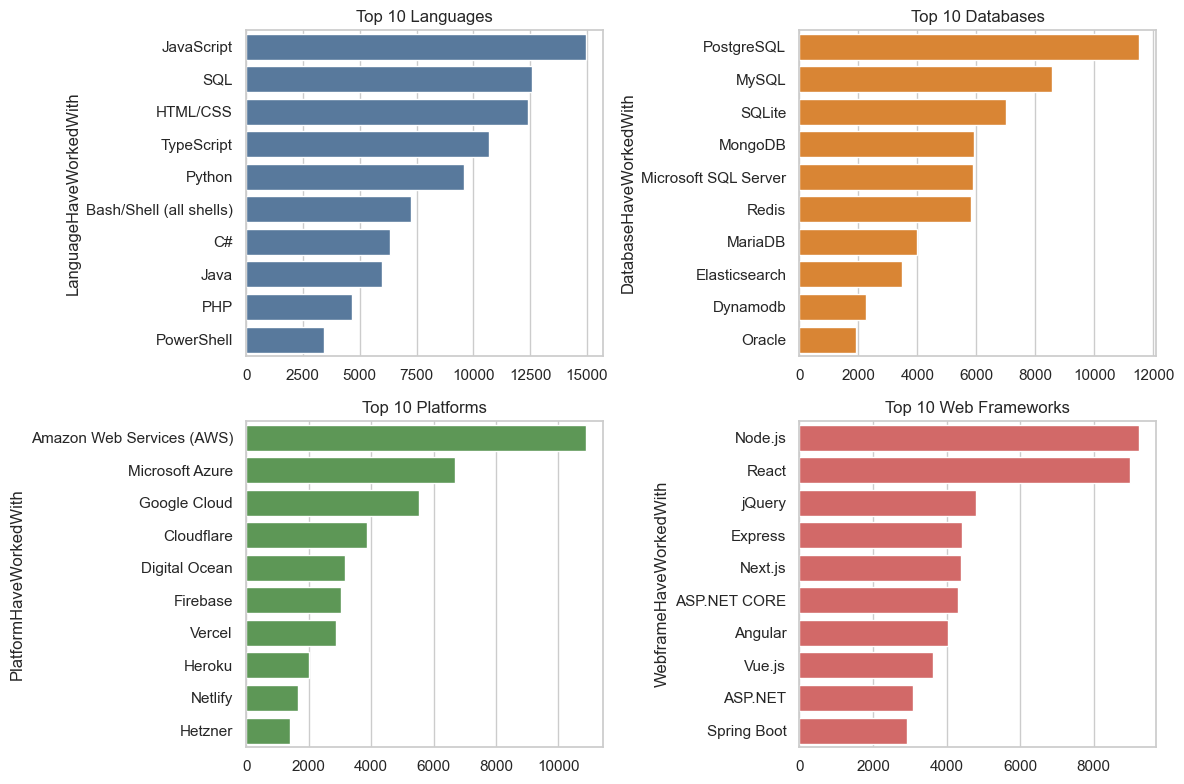

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.barplot(x=top_languages.values, y=top_languages.index, ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Top 10 Languages")

sns.barplot(x=top_databases.values, y=top_databases.index, ax=axes[0, 1], color="#F58518")
axes[0, 1].set_title("Top 10 Databases")

sns.barplot(x=top_platforms.values, y=top_platforms.index, ax=axes[1, 0], color="#54A24B")
axes[1, 0].set_title("Top 10 Platforms")

sns.barplot(x=top_webframes.values, y=top_webframes.index, ax=axes[1, 1], color="#E45756")
axes[1, 1].set_title("Top 10 Web Frameworks")

plt.tight_layout()
plt.savefig("images/01_top_skills_tools.png", dpi=300, bbox_inches="tight")
plt.show()

### Visualization: Age Distribution

Notes:
- Ages are midpoint values from ranges, so the distribution is approximate.
- Non-range responses are excluded, which can reduce sample size.
- The shape may reflect survey reach more than the overall developer population.

Suggestions:
- Segment by YearsCodePro or role to see age and experience alignment.
- Consider broader age cohorts to stabilize comparisons.

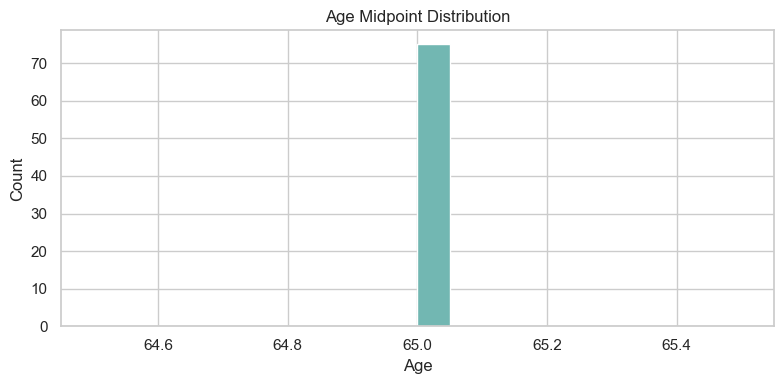

In [ ]:
if "Age_Midpoint" in df.columns:
    plt.figure(figsize=(8, 4))
    df["Age_Midpoint"].dropna().plot(kind="hist", bins=20, color="#72B7B2")
    plt.title("Age Midpoint Distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.savefig("images/02_age_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

### Visualization: Top Countries and Job Satisfaction

Notes:
- Country counts show response concentration, not population share.
- Job satisfaction depends on role, compensation, and regional context.

Suggestions:
- Normalize by population or tech workforce when possible.
- Compare job satisfaction by remote status or compensation band.

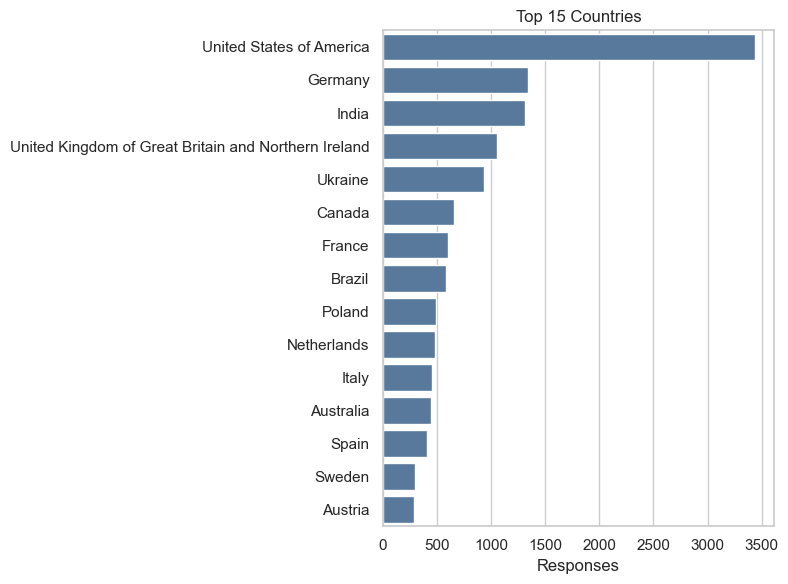

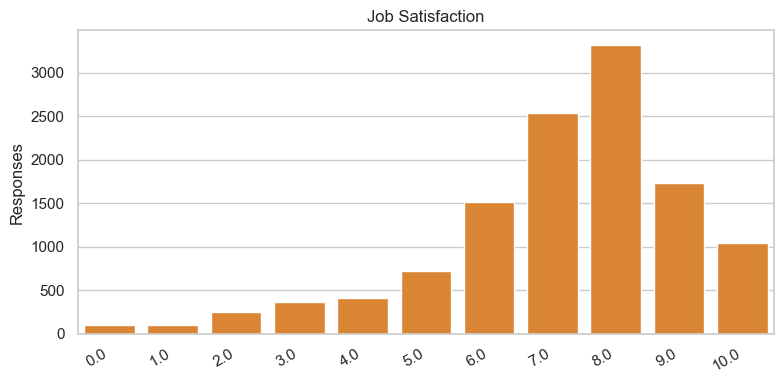

In [ ]:
if "Country" in df.columns:
    top_countries = df["Country"].value_counts().head(15)
    plt.figure(figsize=(8, 6))
    sns.barplot(x=top_countries.values, y=top_countries.index, color="#4C78A8")
    plt.title("Top 15 Countries")
    plt.xlabel("Responses")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig("images/03_top_countries.png", dpi=300, bbox_inches="tight")
    plt.show()

if "JobSat" in df.columns:
    job_sat = df["JobSat"].value_counts()
    plt.figure(figsize=(8, 4))
    sns.barplot(x=job_sat.index, y=job_sat.values, color="#F58518")
    plt.title("Job Satisfaction")
    plt.xlabel("")
    plt.ylabel("Responses")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig("images/04_job_satisfaction.png", dpi=300, bbox_inches="tight")
    plt.show()

### Visualization: Compensation Distribution and Remote Work

Notes:
- Compensation is right-skewed; trimming helps reveal typical ranges.
- Remote work categories are self-reported and may vary by region.

Suggestions:
- Use a log scale to compare spread across categories.
- Break down by country or role to control for mix effects.

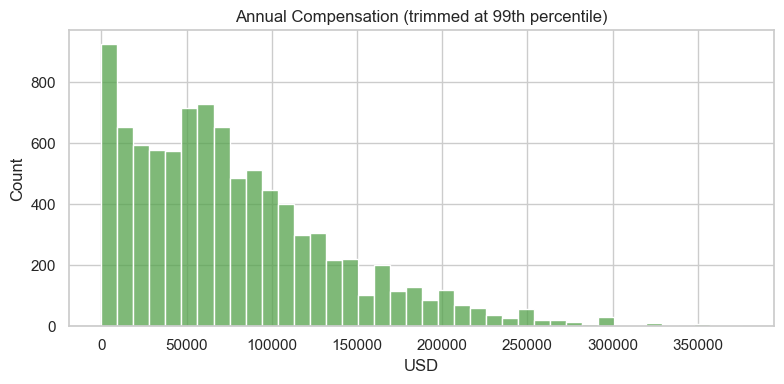

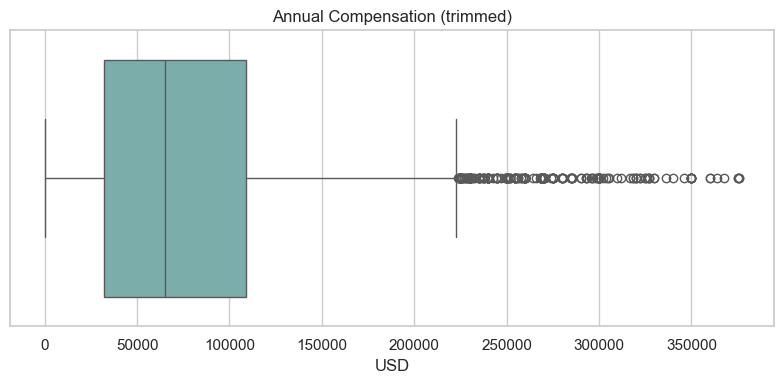

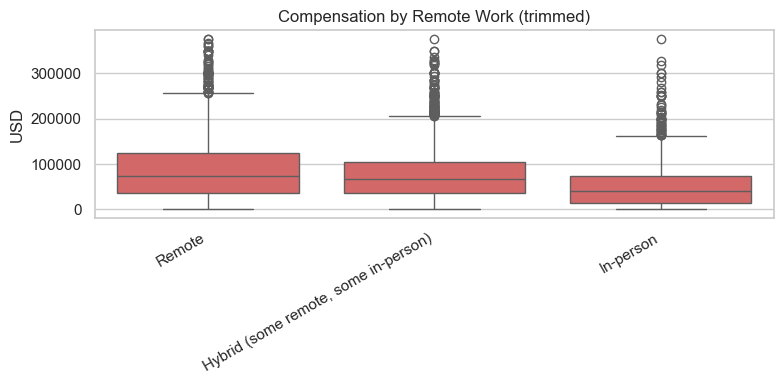

In [ ]:
if "ConvertedCompYearly" in df.columns:
    comp = df["ConvertedCompYearly"].dropna()
    comp = comp[comp > 0]
    if len(comp) > 0:
        upper = comp.quantile(0.99)
        comp_trim = comp[comp <= upper]
        plt.figure(figsize=(8, 4))
        sns.histplot(comp_trim, bins=40, color="#54A24B")
        plt.title("Annual Compensation (trimmed at 99th percentile)")
        plt.xlabel("USD")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.savefig("images/05_compensation_distribution.png", dpi=300, bbox_inches="tight")
        plt.show()

        plt.figure(figsize=(8, 4))
        sns.boxplot(x=comp_trim, color="#72B7B2")
        plt.title("Annual Compensation (trimmed)")
        plt.xlabel("USD")
        plt.tight_layout()
        plt.savefig("images/06_compensation_boxplot.png", dpi=300, bbox_inches="tight")
        plt.show()

if "ConvertedCompYearly" in df.columns and "RemoteWork" in df.columns:
    df_comp = df[["ConvertedCompYearly", "RemoteWork"]].dropna()
    df_comp = df_comp[df_comp["ConvertedCompYearly"] > 0]
    if not df_comp.empty:
        upper = df_comp["ConvertedCompYearly"].quantile(0.99)
        df_comp = df_comp[df_comp["ConvertedCompYearly"] <= upper]
        order = df_comp["RemoteWork"].value_counts().index
        plt.figure(figsize=(8, 4))
        sns.boxplot(data=df_comp, x="RemoteWork", y="ConvertedCompYearly", order=order, color="#E45756")
        plt.title("Compensation by Remote Work (trimmed)")
        plt.xlabel("")
        plt.ylabel("USD")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig("images/07_compensation_by_remote.png", dpi=300, bbox_inches="tight")
        plt.show()

### Visualization: Experience vs Compensation and Correlations

Notes:
- The relationship is usually positive but noisy, with wide variance.
- Correlations summarize linear relationships only and are sensitive to outliers.

Suggestions:
- Add a trend line or median band by experience buckets.
- Treat correlations as directional signals, not causal claims.

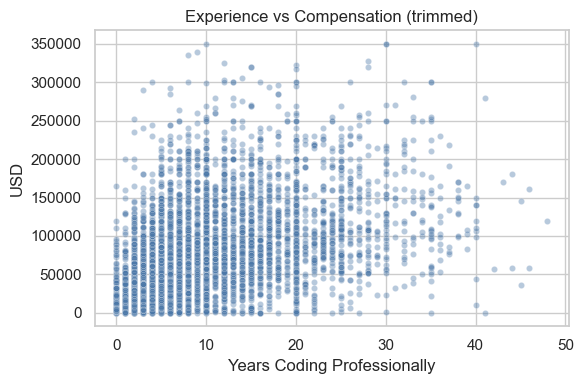

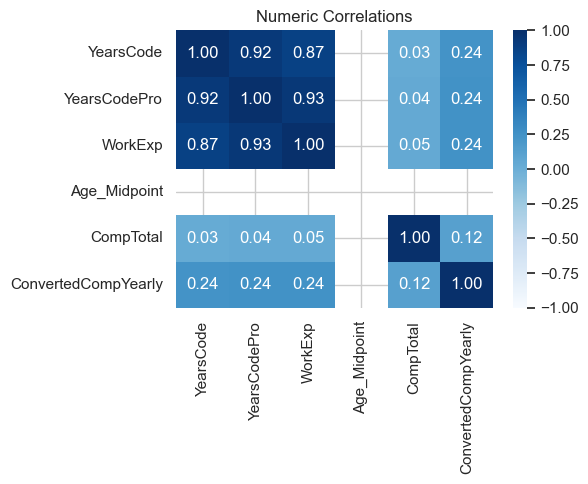

In [ ]:
if "YearsCodePro" in df.columns and "ConvertedCompYearly" in df.columns:
    sample = df[["YearsCodePro", "ConvertedCompYearly"]].dropna()
    sample = sample[(sample["YearsCodePro"] >= 0) & (sample["ConvertedCompYearly"] > 0)]
    if len(sample) > 5000:
        sample = sample.sample(5000, random_state=42)
    if not sample.empty:
        upper = sample["ConvertedCompYearly"].quantile(0.99)
        sample = sample[sample["ConvertedCompYearly"] <= upper]
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=sample, x="YearsCodePro", y="ConvertedCompYearly", alpha=0.4, s=20, color="#4C78A8")
        plt.title("Experience vs Compensation (trimmed)")
        plt.xlabel("Years Coding Professionally")
        plt.ylabel("USD")
        plt.tight_layout()
        plt.savefig("images/08_experience_vs_compensation.png", dpi=300, bbox_inches="tight")
        plt.show()

corr_cols = ["YearsCode", "YearsCodePro", "WorkExp", "Age_Midpoint", "CompTotal", "ConvertedCompYearly"]
available = [col for col in corr_cols if col in df.columns]
if len(available) >= 2:
    corr = df[available].corr(numeric_only=True)
    plt.figure(figsize=(6, 5))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
    plt.title("Numeric Correlations")
    plt.tight_layout()
    plt.savefig("images/09_correlations_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()

### Visualization: Remote Work Mix by Top Countries

Notes:
- Each bar sums to 100 percent, showing within-country remote mix.
- Only the top countries by response count are included.

Suggestions:
- Set a minimum sample size to avoid unstable percentages.
- Compare the remote mix with compensation or job satisfaction.

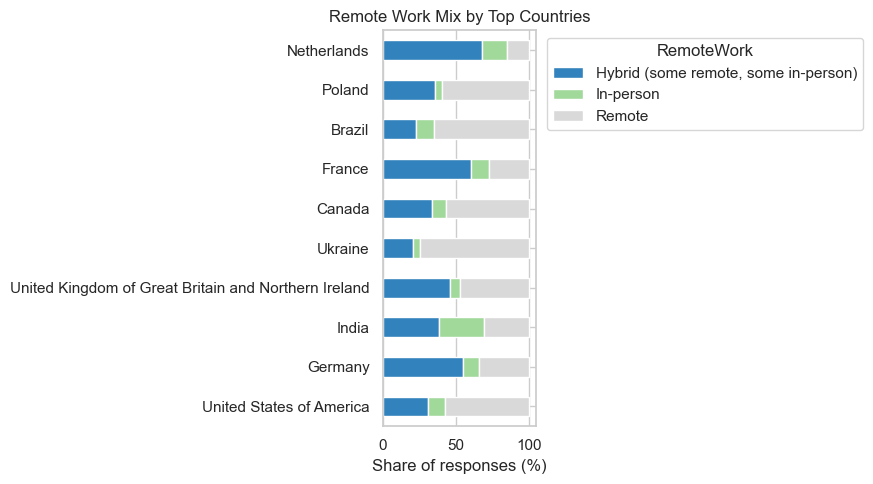

In [ ]:
if "Country" in df.columns and "RemoteWork" in df.columns:
    top_countries = df["Country"].value_counts().head(10).index
    subset = df[df["Country"].isin(top_countries)]
    mix = pd.crosstab(subset["Country"], subset["RemoteWork"], normalize="index") * 100
    mix = mix.loc[top_countries]
    mix.plot(kind="barh", stacked=True, figsize=(9, 5), colormap="tab20c")
    plt.title("Remote Work Mix by Top Countries")
    plt.xlabel("Share of responses (%)")
    plt.ylabel("")
    plt.legend(title="RemoteWork", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig("images/10_remote_work_by_country.png", dpi=300, bbox_inches="tight")
    plt.show()

### Visualization: AI Tool Adoption

Notes:
- Counts are multi-select mentions, so totals can exceed respondents.
- A tool can appear in both current and interested lists.

Suggestions:
- Compute an interest gap (interested minus current) to spot growth areas.
- Focus on tools with high interest but low current use.

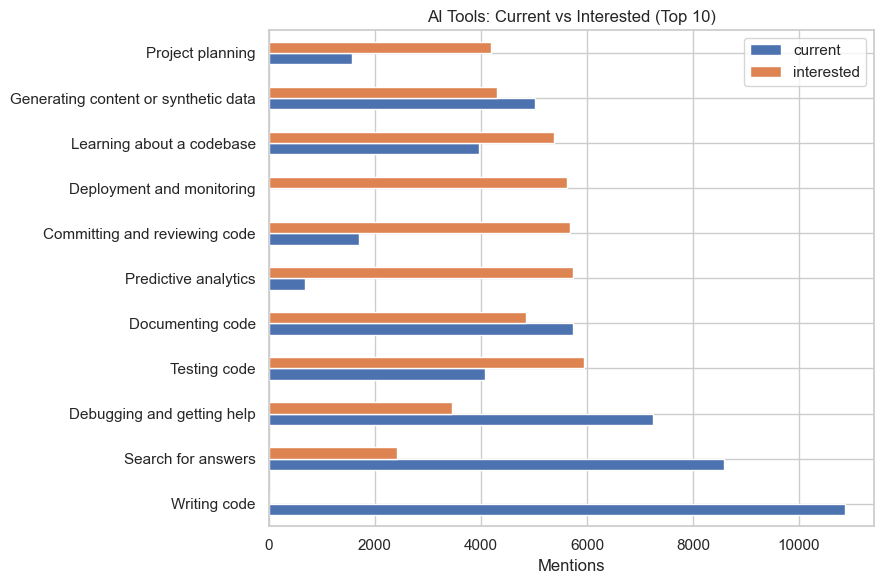

In [ ]:
if "AIToolCurrently_Using" in df.columns and "AIToolInterested_in_Using" in df.columns:
    ai_current = top_counts(df, "AIToolCurrently_Using", 10)
    ai_interested = top_counts(df, "AIToolInterested_in_Using", 10)
    ai_df = pd.concat([ai_current, ai_interested], axis=1)
    ai_df.columns = ["current", "interested"]
    ai_df = ai_df.fillna(0).astype(int)
    ai_df["max"] = ai_df.max(axis=1)
    ai_df = ai_df.sort_values("max", ascending=False).drop(columns="max")
    ai_df.plot(kind="barh", figsize=(9, 6))
    plt.title("AI Tools: Current vs Interested (Top 10)")
    plt.xlabel("Mentions")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig("images/12_ai_tools_adoption.png", dpi=300, bbox_inches="tight")
    plt.show()

## Tech Interest Gap: Languages and Databases

Notes:
- Gap = want count minus have count; a positive gap signals rising interest.
- A minimum threshold is applied to avoid noise from tiny categories.

Suggestions:
- Treat gap leaders as "next wave" hiring and training priorities.
- Pair gap with absolute counts to avoid over-weighting niche tools.

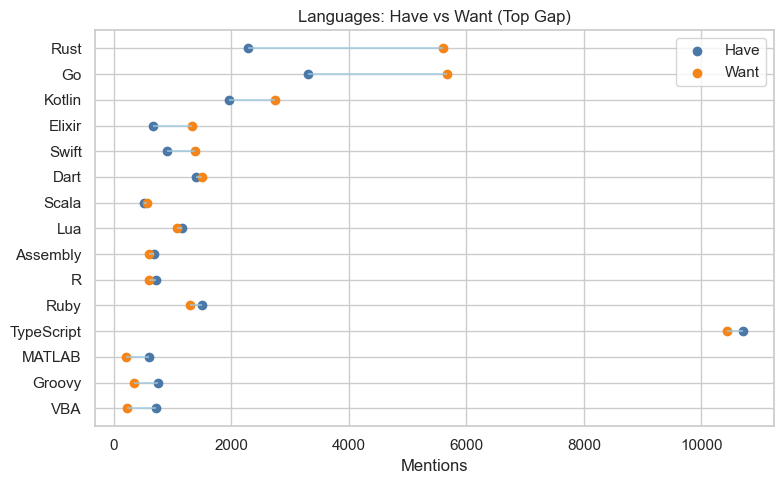

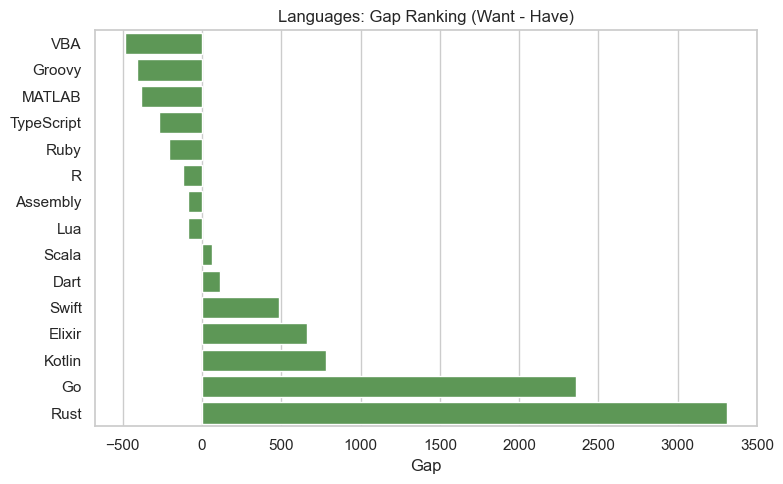

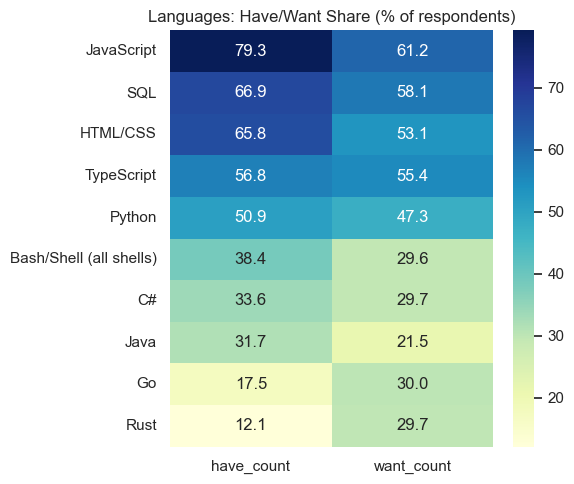

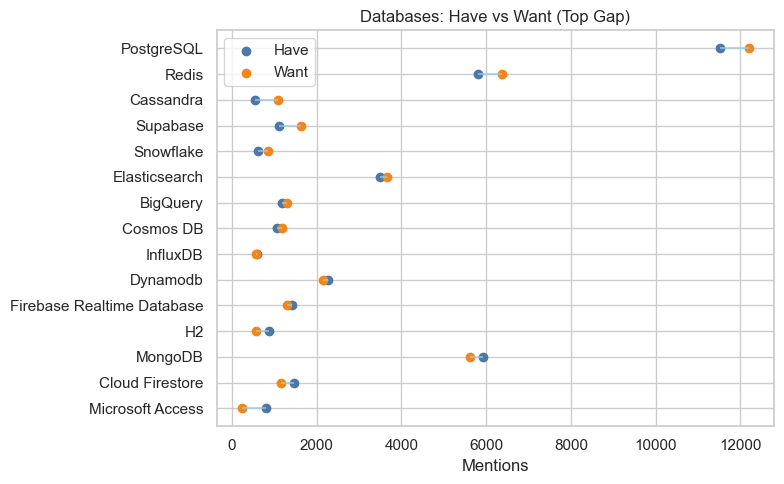

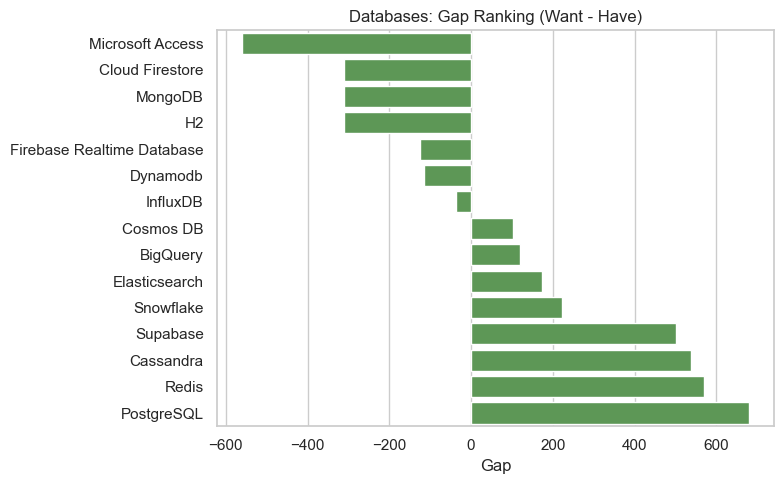

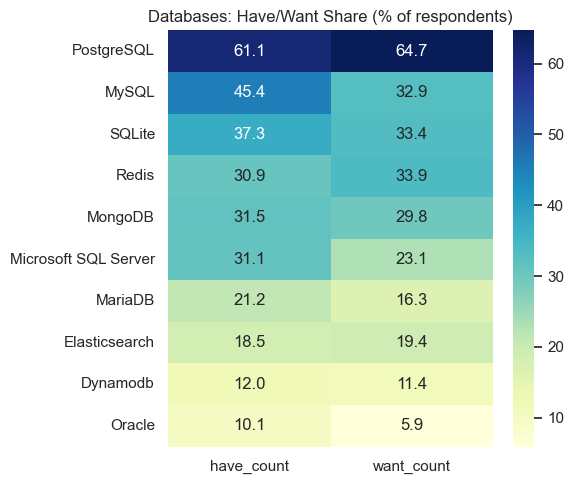

In [ ]:
def plot_gap_panels(gap_df, title_prefix, top_n=15, heat_n=10):
    if gap_df.empty:
        print(f"No data available for {title_prefix} after thresholds.")
        return

    top = gap_df.head(top_n).sort_values("gap")
    y = np.arange(len(top))
    plt.figure(figsize=(8, 5))
    plt.hlines(y, top["have_count"], top["want_count"], color="#9ecae1", alpha=0.7)
    plt.scatter(top["have_count"], y, label="Have", color="#4C78A8")
    plt.scatter(top["want_count"], y, label="Want", color="#F58518")
    plt.yticks(y, top.index)
    plt.title(f"{title_prefix}: Have vs Want (Top Gap)")
    plt.xlabel("Mentions")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"images/14_{title_prefix.lower()}_gap_dumbbell.png", dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(8, 5))
    sns.barplot(x=top["gap"], y=top.index, color="#54A24B")
    plt.title(f"{title_prefix}: Gap Ranking (Want - Have)")
    plt.xlabel("Gap")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(f"images/15_{title_prefix.lower()}_gap_ranking.png", dpi=300, bbox_inches="tight")
    plt.show()

    heat_items = (
        gap_df.assign(max_count=gap_df[["have_count", "want_count"]].max(axis=1))
        .sort_values("max_count", ascending=False)
        .head(heat_n)
        .index
    )
    heat = gap_df.loc[heat_items, ["have_count", "want_count"]]
    heat_pct = (heat / len(df) * 100).round(2)
    plt.figure(figsize=(6, 5))
    sns.heatmap(heat_pct, annot=True, fmt=".1f", cmap="YlGnBu")
    plt.title(f"{title_prefix}: Have/Want Share (% of respondents)")
    plt.tight_layout()
    plt.savefig(f"images/16_{title_prefix.lower()}_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_gap_panels(language_gap, "Languages")
plot_gap_panels(database_gap, "Databases")

## Executive Report

### Summary
- This notebook provides a clean, reproducible workflow for exploring the survey data, standardizing key fields, and visualizing adoption, satisfaction, and compensation patterns.
- The visual set emphasizes practical decision support: what is most common today, where interest is rising, and how compensation and experience relate.

### Key Insights (from the views generated here)
- Skill and tool usage is concentrated in a small set of languages, databases, and frameworks, with a long tail that can signal niche opportunities.
- Compensation is heavily right-skewed; trimmed views and medians are more representative than averages.
- Experience and compensation typically move together, but with wide variance that suggests role, geography, and company size are strong confounders.
- Remote work mix varies by country, indicating location-specific norms and policy constraints.
- AI tool adoption shows a gap between current usage and stated interest, which is useful for prioritizing enablement.

### Data Quality Notes
- Many fields are multi-select, so counts represent mentions, not respondents.
- Self-reported compensation and experience can introduce noise; trimming and log scales help stabilize interpretation.
- Country-level counts reflect survey reach; use minimum sample sizes before comparing groups.

